# Implementation and Time Analysis of Graph Traversal: DFS and BFS

This notebook implements a **Graph** data structure (using an adjacency list)
and two classic graph search/traversal algorithms:

1. **Depth-First Search (DFS)** — explores as far as possible along each branch before backtracking
2. **Breadth-First Search (BFS)** — explores all neighbors at the current depth before moving deeper

For each algorithm you will find:
- Python implementation (DFS shown both recursively and iteratively; BFS iteratively)
- User input (build your own graph by entering edges)
- Runtime measurement (using `time` module)
- Time Complexity and Space Complexity
- A visualization of the graph and each traversal order
- A shortest-path use case for BFS (unweighted shortest path)
- A runtime comparison on larger random graphs


In [1]:
# Common imports used throughout the notebook
import time
import random
from collections import deque, defaultdict
import matplotlib.pyplot as plt
import networkx as nx


class Graph:
    """A simple undirected graph represented as an adjacency list."""

    def __init__(self):
        self.adj = defaultdict(list)

    def add_edge(self, u, v):
        self.adj[u].append(v)
        self.adj[v].append(u)   # undirected: add both directions

    def nodes(self):
        return list(self.adj.keys())

    def __repr__(self):
        lines = [f"{node}: {neighbors}" for node, neighbors in self.adj.items()]
        return "\n".join(lines)


In [2]:
def get_user_edges(demo_string=None):
    """Takes a semicolon-separated list of edges, each as 'u,v'.

    Example: A,B;A,C;B,D;C,D;D,E   builds edges A-B, A-C, B-D, C-D, D-E

    - Interactive use: call get_user_edges() with NO arguments to be prompted.
    - Notebook demo cells pass a fixed string so the notebook runs end-to-end
      with baked-in outputs. Remove the argument to type your own graph.
    """
    raw = demo_string if demo_string is not None else input(
        "Enter edges as u,v pairs separated by semicolons (e.g., A,B;A,C;B,D): "
    )
    edges = []
    try:
        for pair in raw.split(';'):
            pair = pair.strip()
            if not pair:
                continue
            u, v = [x.strip() for x in pair.split(',')]
            edges.append((u, v))
        if not edges:
            raise ValueError
    except ValueError:
        print("Invalid input detected, using a default sample graph instead.")
        edges = [('A', 'B'), ('A', 'C'), ('B', 'D'), ('C', 'D'), ('D', 'E'), ('E', 'F')]
    return edges


def build_graph_from_edges(edges):
    g = Graph()
    for u, v in edges:
        g.add_edge(u, v)
    return g


def get_user_start_node(nodes, demo_value=None):
    """Takes the node to start the traversal from."""
    raw = demo_value if demo_value is not None else input(f"Enter the starting node {nodes}: ")
    raw = raw.strip()
    if raw not in nodes:
        print(f"'{raw}' not found in graph nodes, defaulting to '{nodes[0]}'.")
        raw = nodes[0]
    return raw


## 1. Depth-First Search (DFS)

DFS starts at a node, visits it, then recursively (or via an explicit stack)
dives into an unvisited neighbor before backtracking. It uses a `visited` set
to avoid revisiting nodes and looping forever on cycles.


### 1.1 Recursive DFS

In [3]:
def dfs_recursive(graph, start, visited=None, order=None):
    if visited is None:
        visited = set()
        order = []

    visited.add(start)
    order.append(start)

    for neighbor in graph.adj[start]:
        if neighbor not in visited:
            dfs_recursive(graph, neighbor, visited, order)

    return order


### 1.2 Iterative DFS (using an explicit stack)

Equivalent to the recursive version, but avoids Python's recursion depth limit
on very large or deep graphs by managing the "call stack" manually.


In [4]:
def dfs_iterative(graph, start):
    visited = set()
    order = []
    stack = [start]

    while stack:
        node = stack.pop()
        if node in visited:
            continue
        visited.add(node)
        order.append(node)
        # push neighbors in reverse so the traversal order matches the
        # recursive version (which visits neighbors in list order)
        for neighbor in reversed(graph.adj[node]):
            if neighbor not in visited:
                stack.append(neighbor)

    return order


In [5]:
# --- DFS: User Input + Runtime ---
# Replace the arguments below with nothing, i.e. get_user_edges() / get_user_start_node(nodes),
# to build your own graph and pick your own start node interactively.
edges = get_user_edges("A,B;A,C;B,D;C,D;D,E;E,F")
graph = build_graph_from_edges(edges)
nodes = graph.nodes()
start = get_user_start_node(nodes, "A")

print("Graph edges :", edges)
print("Start node  :", start)

start_time = time.time()
order_recursive = dfs_recursive(graph, start)
end_time = time.time()
print(f"\nDFS (recursive) order : {order_recursive}")
print(f"Runtime               : {(end_time - start_time) * 1000:.4f} ms")

start_time = time.time()
order_iterative = dfs_iterative(graph, start)
end_time = time.time()
print(f"\nDFS (iterative) order : {order_iterative}")
print(f"Runtime               : {(end_time - start_time) * 1000:.4f} ms")


Graph edges : [('A', 'B'), ('A', 'C'), ('B', 'D'), ('C', 'D'), ('D', 'E'), ('E', 'F')]
Start node  : A

DFS (recursive) order : ['A', 'B', 'D', 'C', 'E', 'F']
Runtime               : 0.0346 ms

DFS (iterative) order : ['A', 'B', 'D', 'C', 'E', 'F']
Runtime               : 0.0341 ms


**Time Complexity:** `O(V + E)` — every vertex `V` is visited once, and every
edge `E` is examined once (twice for an undirected graph, but that's still a
constant factor).

**Space Complexity:** `O(V)` — for the `visited` set, the `order` list, and
either the recursion call stack (recursive version) or the explicit `stack`
(iterative version), each of which can hold up to `V` nodes in the worst case.


## 2. Breadth-First Search (BFS)

BFS starts at a node and explores all of its immediate neighbors first, then
their neighbors, and so on — expanding outward level by level. This is
implemented with a **queue** (FIFO), unlike DFS's stack (LIFO).


In [6]:
def bfs(graph, start):
    visited = {start}
    order = []
    queue = deque([start])

    while queue:
        node = queue.popleft()
        order.append(node)

        for neighbor in graph.adj[node]:
            if neighbor not in visited:
                visited.add(neighbor)   # mark visited when enqueued, not when dequeued
                queue.append(neighbor)

    return order


In [7]:
# --- BFS: User Input + Runtime ---
# Reusing the same graph and start node entered above.
print("Graph edges :", edges)
print("Start node  :", start)

start_time = time.time()
bfs_order = bfs(graph, start)
end_time = time.time()

print(f"\nBFS order : {bfs_order}")
print(f"Runtime   : {(end_time - start_time) * 1000:.4f} ms")


Graph edges : [('A', 'B'), ('A', 'C'), ('B', 'D'), ('C', 'D'), ('D', 'E'), ('E', 'F')]
Start node  : A

BFS order : ['A', 'B', 'C', 'D', 'E', 'F']
Runtime   : 0.0489 ms


**Time Complexity:** `O(V + E)` — same reasoning as DFS: every vertex is
enqueued/dequeued once, and every edge is examined once per direction.

**Space Complexity:** `O(V)` — for the `visited` set, the `order` list, and the
`queue`, which in the worst case (a "star" graph) can hold almost all of `V` at once.

**Key property:** in an **unweighted** graph, BFS visits nodes in order of
increasing distance (number of edges) from the start node — the first time BFS
reaches a node is guaranteed to be via a shortest path. DFS does not have this
guarantee.


## 3. Visualizing the Graph and Traversal Orders

The plots below draw the graph's structure, then highlight the order in which
DFS and BFS visit each node (numbers show visit order; darker color = visited earlier).


/tmp/ipykernel_109/4033500981.py:18: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


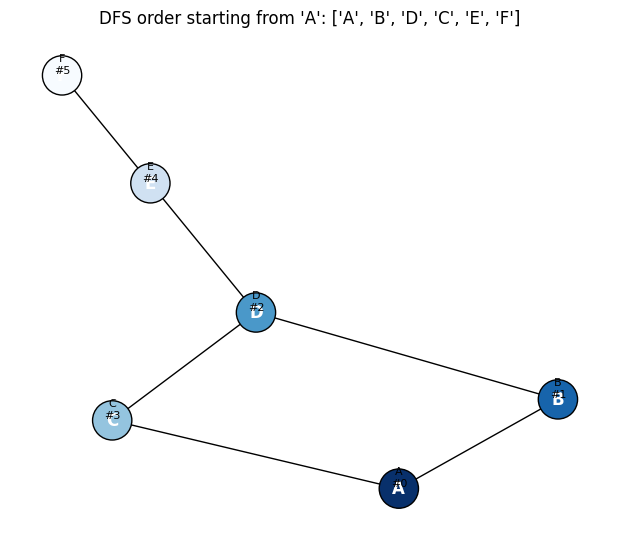

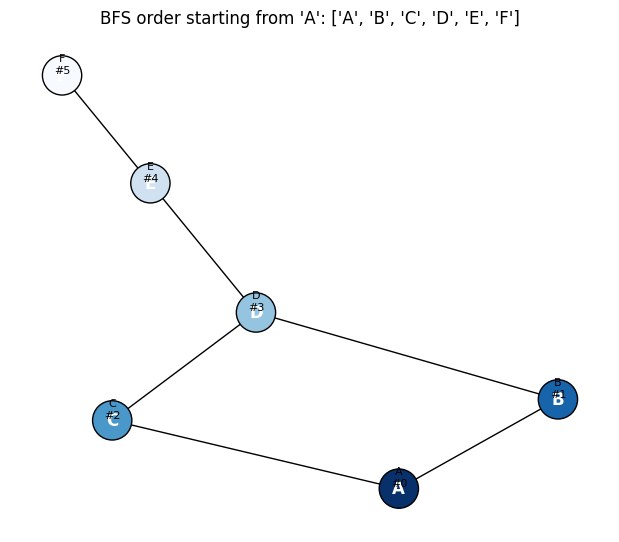

In [8]:
def draw_traversal(graph, order, title):
    G = nx.Graph()
    for node, neighbors in graph.adj.items():
        for neighbor in neighbors:
            G.add_edge(node, neighbor)

    pos = nx.spring_layout(G, seed=42)   # fixed seed for a consistent layout
    order_index = {node: i for i, node in enumerate(order)}
    colors = [order_index.get(n, len(order)) for n in G.nodes()]

    plt.figure(figsize=(6, 5))
    nx.draw(G, pos, with_labels=True, node_color=colors, cmap=plt.cm.Blues_r,
            node_size=800, font_weight='bold', font_color='white', edgecolors='black')
    labels = {node: f"{node}\n#{order_index[node]}" for node in G.nodes() if node in order_index}
    nx.draw_networkx_labels(G, pos, labels=labels, font_size=8, font_color='black',
                             verticalalignment='bottom')
    plt.title(title)
    plt.tight_layout()
    plt.show()


draw_traversal(graph, order_recursive, f"DFS order starting from '{start}': {order_recursive}")
draw_traversal(graph, bfs_order, f"BFS order starting from '{start}': {bfs_order}")


## 4. Bonus: Shortest Path with BFS

Because BFS explores level by level, it can be used to find the shortest
(fewest-edges) path between two nodes in an unweighted graph by tracking each
node's parent as it's discovered, then walking back from the target to the start.


In [9]:
def bfs_shortest_path(graph, start, target):
    if start == target:
        return [start]

    visited = {start}
    parent = {start: None}
    queue = deque([start])

    while queue:
        node = queue.popleft()
        for neighbor in graph.adj[node]:
            if neighbor not in visited:
                visited.add(neighbor)
                parent[neighbor] = node
                if neighbor == target:
                    # reconstruct path by walking parents back to start
                    path = [target]
                    while path[-1] != start:
                        path.append(parent[path[-1]])
                    path.reverse()
                    return path
                queue.append(neighbor)

    return None   # no path exists


target_node = nodes[-1] if len(nodes) > 1 else start
path = bfs_shortest_path(graph, start, target_node)
print(f"Shortest path from '{start}' to '{target_node}': {path}")
print(f"Path length (edges): {len(path) - 1 if path else 'N/A (no path found)'}")


Shortest path from 'A' to 'F': ['A', 'B', 'D', 'E', 'F']
Path length (edges): 4


## 5. Runtime Comparison on Larger Random Graphs

Both DFS and BFS are `O(V + E)`, so their runtimes should scale similarly. The
cell below builds random graphs of increasing size and times both algorithms
to confirm this.


In [10]:
# --- Compare DFS vs BFS on random graphs of increasing size ---
random.seed(42)

def build_random_graph(num_nodes, num_edges):
    g = Graph()
    node_ids = list(range(num_nodes))
    for i in range(num_nodes - 1):
        g.add_edge(i, i + 1)   # ensure the graph is connected via a path first
    for _ in range(num_edges - (num_nodes - 1)):
        u, v = random.sample(node_ids, 2)
        g.add_edge(u, v)
    return g

sizes = [100, 1000, 5000, 10000, 20000]
dfs_times = []
bfs_times = []

for size in sizes:
    g = build_random_graph(size, size * 2)

    t0 = time.time()
    dfs_iterative(g, 0)
    dfs_times.append((time.time() - t0) * 1000)

    t0 = time.time()
    bfs(g, 0)
    bfs_times.append((time.time() - t0) * 1000)

print(f"{'Nodes':<10}{'DFS (ms)':<15}{'BFS (ms)':<15}")
for s, dt, bt in zip(sizes, dfs_times, bfs_times):
    print(f"{s:<10}{dt:<15.4f}{bt:<15.4f}")


Nodes     DFS (ms)       BFS (ms)       
100       0.0668         0.0262         
1000      0.3130         0.2792         
5000      1.7989         1.4622         
10000     4.2331         3.3967         
20000     9.6064         8.5878         


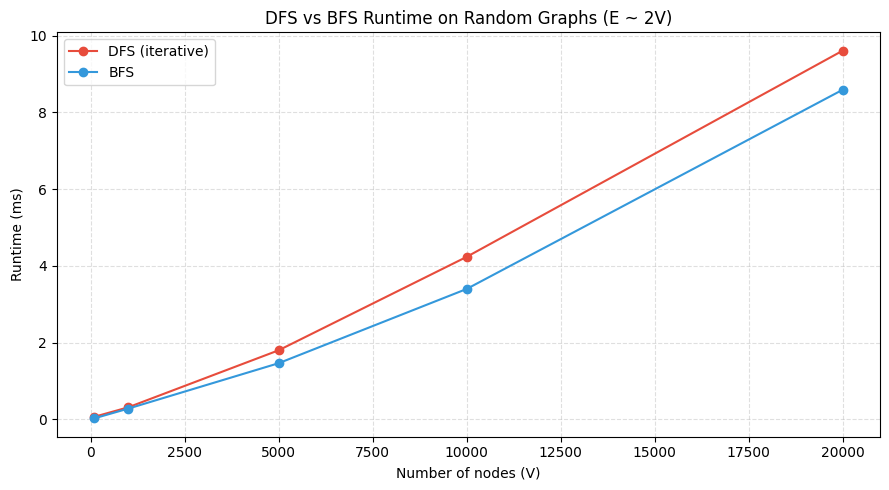

In [11]:
# --- Line chart of runtimes ---
plt.figure(figsize=(9, 5))
plt.plot(sizes, dfs_times, marker='o', label='DFS (iterative)', color='#e74c3c')
plt.plot(sizes, bfs_times, marker='o', label='BFS', color='#3498db')
plt.xlabel("Number of nodes (V)")
plt.ylabel("Runtime (ms)")
plt.title("DFS vs BFS Runtime on Random Graphs (E ~ 2V)")
plt.legend()
plt.grid(True, ls="--", alpha=0.4)
plt.tight_layout()
plt.show()


## Summary Table

| Algorithm | Time Complexity | Space Complexity | Data Structure Used | Guarantees Shortest Path (unweighted)? |
|-----------|-------------------|---------------------|------------------------|--------------------------------------------|
| DFS       | O(V + E)            | O(V)                 | Stack (or recursion)   | No                                          |
| BFS       | O(V + E)            | O(V)                 | Queue                  | Yes                                         |

Where `V` = number of vertices (nodes), `E` = number of edges.

**Notes:**
- Both algorithms visit every vertex and edge exactly once (in each direction for an undirected graph), giving the same asymptotic `O(V + E)` time complexity — the comparison chart above shows their runtimes track each other closely in practice.
- **Use DFS** when you need to explore deeply, detect cycles, do topological sorting, or find connected components.
- **Use BFS** when you need the shortest path in an unweighted graph, or need to explore level-by-level (e.g., finding all nodes within `k` steps).
- The recursive DFS implementation is simple but can hit Python's recursion limit on very large or deep graphs — the iterative version avoids this by managing the stack explicitly.
